# 01 · Exploring MovieLens

Before building any recommender, we look at the data it will learn from.
MovieLens `ml-latest-small` (GroupLens Research): real ratings from real users, 0.5–5 stars.

Questions:
1. How sparse is the data?
2. How skewed is popularity (the "long tail")?
3. How much text (genres, tags) do content-based models have to work with?

In [1]:
import sys
sys.path.insert(0, "../backend")

import matplotlib.pyplot as plt
import numpy as np

from app.recsys.data import LIKE_THRESHOLD, load

plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.spines.top": False, "axes.spines.right": False})
ratings, movies = load()
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 1. Size and sparsity

In [2]:
n_users, n_movies, n_ratings = ratings.userId.nunique(), ratings.movieId.nunique(), len(ratings)
sparsity = 1 - n_ratings / (n_users * n_movies)
liked_share = (ratings.rating >= LIKE_THRESHOLD).mean()
print(f"users={n_users:,}  movies rated={n_movies:,}  ratings={n_ratings:,}")
print(f"sparsity={sparsity:.2%}  (share of user-movie pairs with NO rating)")
print(f"ratings >= {LIKE_THRESHOLD} ('liked'): {liked_share:.1%}")

users=610  movies rated=9,724  ratings=100,836
sparsity=98.30%  (share of user-movie pairs with NO rating)
ratings >= 4.0 ('liked'): 48.2%


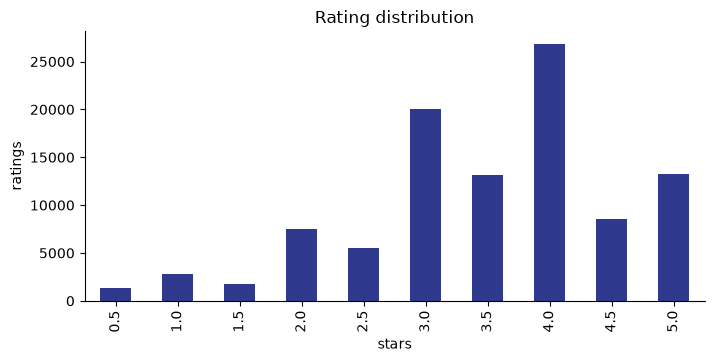

In [3]:
ax = ratings.rating.value_counts().sort_index().plot.bar(color="#2f3a8f")
ax.set(title="Rating distribution", xlabel="stars", ylabel="ratings");

## 2. Popularity is very skewed

top 10% of movies receive 60.0% of all ratings
35.4% of movies were rated only once


median ratings per user: 70, min: 20


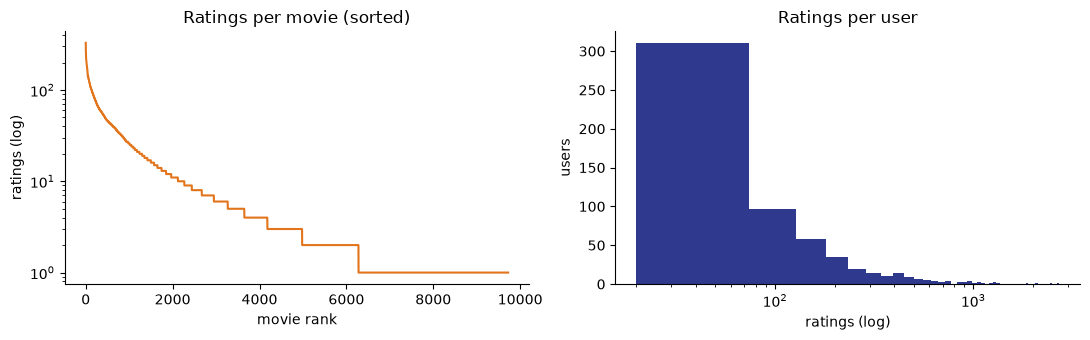

In [4]:
per_movie = ratings.groupby("movieId").size().sort_values(ascending=False)
top10 = per_movie.head(int(len(per_movie) * 0.1)).sum() / per_movie.sum()
once = (per_movie == 1).mean()
print(f"top 10% of movies receive {top10:.1%} of all ratings")
print(f"{once:.1%} of movies were rated only once")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(np.arange(len(per_movie)), per_movie.values, color="#e2741b")
a.set(yscale="log", title="Ratings per movie (sorted)", xlabel="movie rank", ylabel="ratings (log)")
per_user = ratings.groupby("userId").size()
b.hist(per_user, bins=50, color="#2f3a8f")
b.set(xscale="log", title="Ratings per user", xlabel="ratings (log)", ylabel="users")
plt.tight_layout()
print(f"median ratings per user: {per_user.median():.0f}, min: {per_user.min()}")

## 3. What text do content models get?

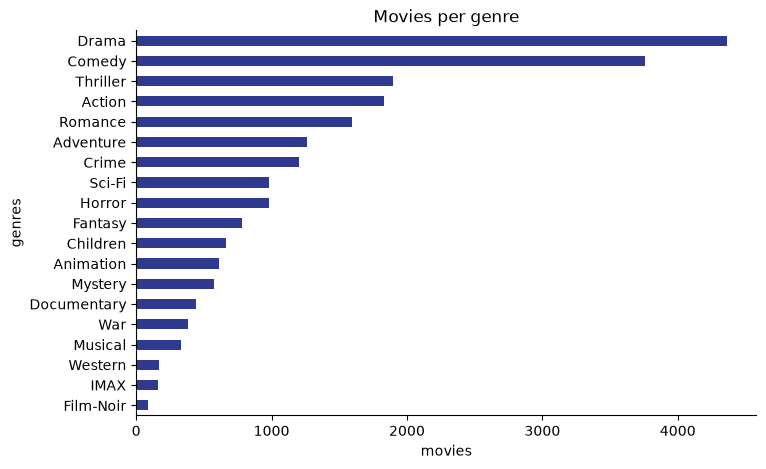

In [5]:
genres = movies.explode("genres").genres.value_counts()
ax = genres.plot.barh(color="#2f3a8f", figsize=(8, 5))
ax.invert_yaxis()
ax.set(title="Movies per genre", xlabel="movies");

In [6]:
has_tags = (movies.tags.str.len() > 0).mean()
rated = movies[movies.movieId.isin(per_movie.index)]
w = rated.movieId.map(per_movie)
tag_weighted = ((rated.tags.str.len() > 0) * w).sum() / w.sum()
print(f"genres per movie (mean): {movies.genres.str.len().mean():.2f}")
print(f"movies with at least one user tag: {has_tags:.1%}")
print(f"... weighted by number of ratings: {tag_weighted:.1%}")
print(f"movies with a TMDB id: {movies.tmdb_id.notna().mean():.1%}")
movies[movies.tags.str.len() > 0].sample(5, random_state=1)[["title", "genres", "tags"]]

genres per movie (mean): 2.26
movies with at least one user tag: 16.1%
... weighted by number of ratings: 47.9%
movies with a TMDB id: 99.9%


,title,genres,tags
375,Carlito's Way (1993),"[Crime, Drama]","[al pacino, gangster, mafia]"
4851,The Butterfly Effect (2004),"[Drama, Sci-Fi, Thriller]","[alternate reality, sci-fi, science fiction, t..."
648,Chain Reaction (1996),"[Action, Adventure, Thriller]",[seen at the cinema]
4012,Bowling for Columbine (2002),[Documentary],[violence in america]
2660,Limelight (1952),"[Comedy, Drama, Romance]",[in netflix queue]


## Findings

1. **Very sparse.** 610 users, 9,724 movies, 100,836 ratings, so 98.3% of user–movie pairs are empty. A model sees about 70 ratings per user (the median), and every user has at least 20.
2. **"Liked" is common.** 48.2% of ratings are 4★ or higher, so `rating >= 4` gives plenty of positive examples.
3. **Strong popularity bias.** The top 10% of movies get 60% of all ratings, and 35.4% of movies were rated only once. A popularity baseline will be hard to beat on accuracy but will recommend a tiny part of the catalog. That's why we also measure **coverage**.
4. **Little text per movie.** On average a movie has 2.3 genres, and only 16% have user tags (48% when weighted by ratings, since popular movies get tagged). Content-based models get thin input here. In the real app we add TMDB overviews and keywords, and 99.9% of movies have a TMDB id.

**What this means for modelling:** collaborative filtering should do well on MovieLens because it has lots of user overlap on popular movies. WIN's real job is different, though: it has to recommend **across categories**, where we have no shared users, only text. So we judge content models on how close they get to collaborative filtering, not only on who wins.